# Instances, Make Local and shared lambdas

**The pickle:** three things that looked impossible.

| # | What you saw | Short answer |
|---|---|---|
| 1 | A fresh instance of `_common_base_0_0.tscn` shows the "Dim Nodes..." messages | It is reading the lambda stored in the **base file** |
| 2 | Click Make Local and the first message becomes "Lo !" | The copy now points at a **different lambda with the same ID**, stored in the **map file** |
| 3 | The base scene seems to show "Lo !" although you never edited it | The base **file** is unchanged; what looks changed is a **live object in memory** (section 8) |

Nothing is corrupted. Five plain facts about how Godot stores and loads scenes combine to produce all three. This notebook builds them up one at a time, starting with the one everything else rests on.

| Section | Fact |
|---|---|
| 1 | **There are two worlds: files on disk and live objects in memory** |
| 2 | A `.tscn` is a text recipe with three kinds of entries |
| 3 | Nodes are copied; resources (your lambdas) are shared |
| 4 | An instance is a link plus diffs; Make Local cuts the link |
| 5 | Sub-resource IDs only mean something inside their own file |
| 6 | How the five facts add up to your pickle |
| 7 | Check the real files yourself (runnable) |
| 8 | Getting out, and the working rules from here on |


## 1. Two worlds: files on disk, live objects in memory

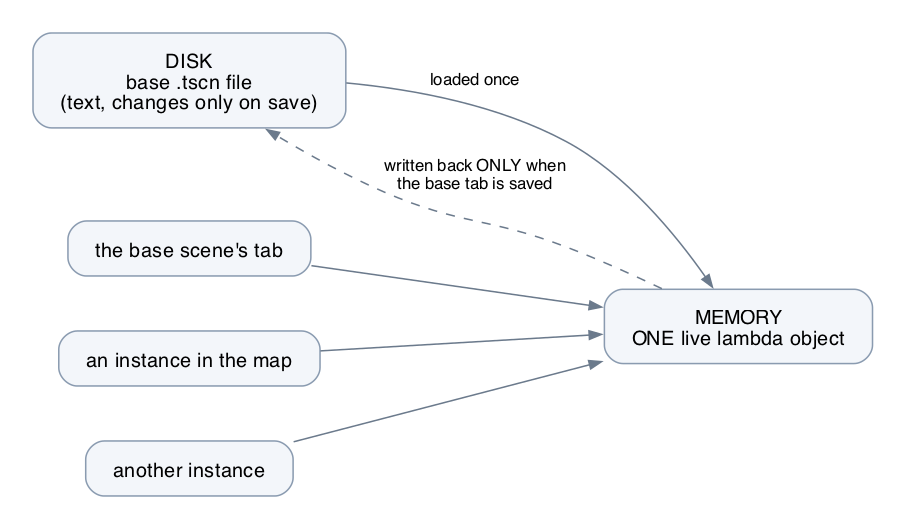

<details><summary>diagram source (graphviz)</summary>

```dot
digraph {
  disk [label="DISK\nbase .tscn file\n(text, changes only on save)"];
  obj [label="MEMORY\nONE live lambda object"];
  tab [label="the base scene's tab"];
  i1 [label="an instance in the map"];
  i2 [label="another instance"];
  disk -> obj [label="loaded once"];
  tab -> obj; i1 -> obj; i2 -> obj;
  obj -> disk [label="written back ONLY when\nthe base tab is saved", style=dashed, constraint=false];
}
```

</details>

This is the first principle. Everything you see in the editor or the game is a **live object in memory**. A `.tscn` file is only a saved description of objects, read when loading and written when saving.

| | Disk (the file) | Memory (the live object) |
|---|---|---|
| What it is | Text describing the lambda | The actual lambda the editor and game use |
| How many | One copy per file | **One object**, however many nodes point at it |
| Changes when | You save the scene that **owns** it | You edit it anywhere, immediately |
| What the Inspector shows | Never the file directly | Always the live object |

So "does changing the resource in one instance change the base?" has two answers:

| Where | Does a change made through one instance show up for the base and for other instances? |
|---|---|
| **Running game** | **Yes.** Every instance points at the same live object, until the game closes |
| **Editor, in memory** | **Yes**, as far as I know. The instance, other instances and the base scene's own tab all show the same live object |
| **The base `.tscn` file on disk** | **No.** Saving the map does not write into the base file. Only saving the base scene's own tab does |

| Consequence | Why it matters |
|---|---|
| "The instance's lambda" and "the base's lambda" are the same object | Editing "one" edits "both"; there is no both |
| The editor can show something the file does not contain | That is what symptom 3 is |
| Saving decides what becomes real | An edit in memory is harmless until the owning scene is saved |
| Reloading throws the memory version away | Scene > Reload Saved Scene brings back what is on disk |

Godot warns when you edit a lambda that belongs to another scene, saying the change will not be kept when you save the current scene. I have not verified the exact wording in your version.


### Feel it: disk and memory drift apart

In [1]:
disk = {"base.tscn": "Dim Nodes..."}                 # the files

live = {"messages": disk["base.tscn"]}                # loading creates ONE live object
base_tab, instance_1, instance_2 = live, live, live   # three views of that one object

instance_1["messages"] = "Lo !"                       # edit "through one instance"

def show(title):
	print(f"{title:<28} base tab: {base_tab['messages']:<14} instance 2: {instance_2['messages']:<14} file: {disk['base.tscn']}")

show("after editing instance 1")

disk["map.tscn"] = "(the map's own nodes and diffs)"  # save the MAP: the base file is not touched
show("after saving the map")

live["messages"] = disk["base.tscn"]                  # Reload Saved Scene: memory goes back to the file
show("after reloading")

instance_1["messages"] = "Lo !"
disk["base.tscn"] = base_tab["messages"]              # save the BASE TAB: now it is real
show("after saving the base tab")

after editing instance 1     base tab: Lo !           instance 2: Lo !           file: Dim Nodes...
after saving the map         base tab: Lo !           instance 2: Lo !           file: Dim Nodes...
after reloading              base tab: Dim Nodes...   instance 2: Dim Nodes...   file: Dim Nodes...
after saving the base tab    base tab: Lo !           instance 2: Lo !           file: Lo !


In [2]:
# ----- student scratchpad -----

## 2. A `.tscn` is a text recipe

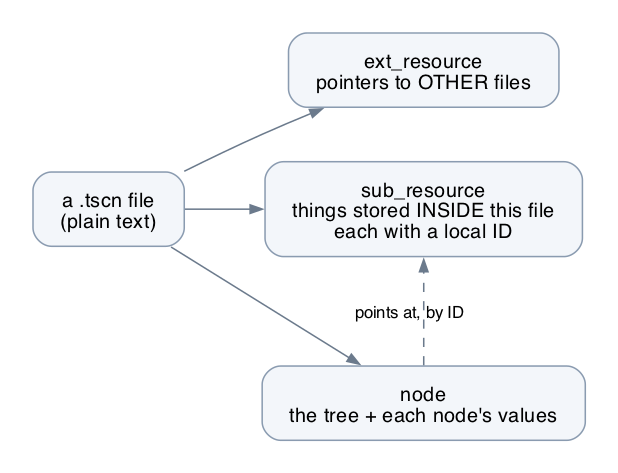

<details><summary>diagram source (graphviz)</summary>

```dot
digraph {
  f [label="a .tscn file\n(plain text)"];
  e [label="ext_resource\npointers to OTHER files"];
  s [label="sub_resource\nthings stored INSIDE this file\neach with a local ID"];
  n [label="node\nthe tree + each node's values"];
  f -> e; f -> s; f -> n;
  n -> s [label="points at, by ID", style=dashed, constraint=false];
}
```

</details>

This is your base scene, trimmed:

```
[ext_resource type="Script" path="res://.../_rpgm_lambda_show_messages.gd" id="4_fxafh"]

[sub_resource type="Resource" id="Resource_kvxu2"]            <- a lambda, stored in this file
script = ExtResource("4_fxafh")
messages = Array[String](["Dim Nodes and Dimmed Scripts ..."])

[node name="_common_base_0_0" type="Node2D"]
[node name="_RPGM_Script" parent="." instance=ExtResource("2_11dvb")]
on_action = Array[...]([SubResource("Resource_kvxu2")])        <- the node POINTS at the lambda
```

| Entry | Meaning | In your case |
|---|---|---|
| `ext_resource` | "Use that other file" | The scripts, `_rpgm_script.tscn`, the portrait scene |
| `sub_resource` | "This thing lives inside me, and its name here is this ID" | The Show Messages lambda, `Resource_kvxu2` |
| `node` | "A node, its parent, and its values" | The event, its script child, its portrait |

**The key detail:** the script node does not *contain* the lambda. It holds `SubResource("Resource_kvxu2")`, which means "the thing called `Resource_kvxu2` in this file".


## 3. Nodes are copied, resources are shared

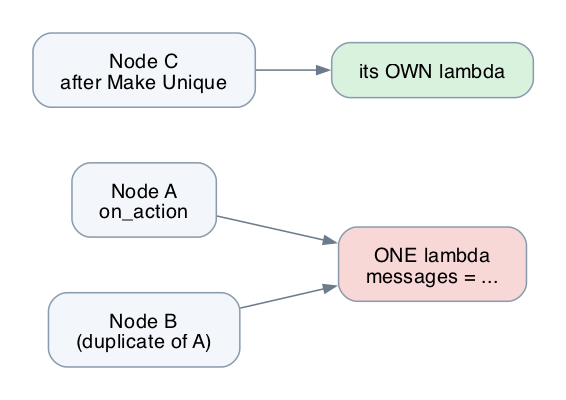

<details><summary>diagram source (graphviz)</summary>

```dot
digraph {
  a [label="Node A\non_action"];
  b [label="Node B\n(duplicate of A)"];
  l [label="ONE lambda\nmessages = ...", fillcolor="#f8d7d7"];
  c [label="Node C\nafter Make Unique"];
  l2 [label="its OWN lambda", fillcolor="#d9f2dd"];
  a -> l; b -> l; c -> l2;
}
```

</details>

| | Node | Resource (a lambda) |
|---|---|---|
| Duplicate (Cmd+D) | A new, separate node | **Not copied.** The new node points at the same lambda |
| Instance a scene twice | Two separate sets of nodes | Both point at the same lambda |
| Make Local | The nodes become your own copies | **Not copied** |
| Edit it | Changes that one node | Changes it for **every node pointing at it** |
| How to get a separate one | (automatic) | Right-click it in the Inspector, **Make Unique** |

This is fact 1 seen from the node side: several nodes, one live object. It is also the "resources are shared" row from `godot-lifecycles.ipynb`.


### Feel it: one lambda, two owners

In [3]:
import copy

lambda_1 = {"messages": ["Dim Nodes..."]}

node_a = {"name": "_common_base_0_1", "on_action": [lambda_1]}
node_b = dict(node_a, name="_common_base_0_2")       # duplicate the NODE (the lambda is not copied)

print("before:", node_a["on_action"][0]["messages"], "|", node_b["on_action"][0]["messages"])

node_b["on_action"][0]["messages"][0] = "Lo !"        # edit the message "on node B"
print("after: ", node_a["on_action"][0]["messages"], "|", node_b["on_action"][0]["messages"])
print("same lambda object?", node_a["on_action"][0] is node_b["on_action"][0])

# Make Unique = give node C its own copy first
node_c = dict(node_a, name="_common_base_0_3", on_action=[copy.deepcopy(lambda_1)])
node_c["on_action"][0]["messages"][0] = "Only me"
print("\nafter Make Unique on C:", node_a["on_action"][0]["messages"], "|", node_c["on_action"][0]["messages"])

before: ['Dim Nodes...'] | ['Dim Nodes...']
after:  ['Lo !'] | ['Lo !']
same lambda object? True

after Make Unique on C: ['Lo !'] | ['Only me']


In [4]:
# ----- student scratchpad -----

## 4. An instance is a link plus diffs

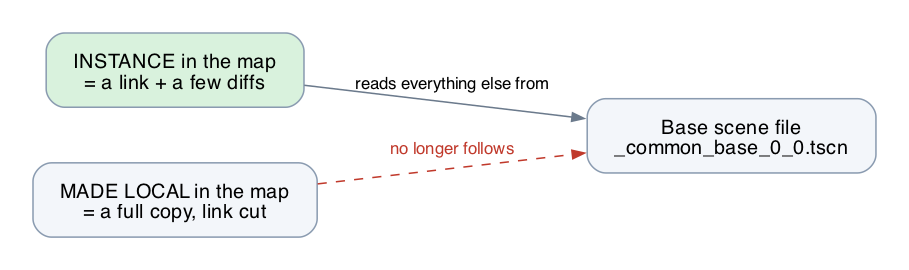

<details><summary>diagram source (graphviz)</summary>

```dot
digraph {
  base [label="Base scene file\n_common_base_0_0.tscn"];
  inst [label="INSTANCE in the map\n= a link + a few diffs", fillcolor="#d9f2dd"];
  local [label="MADE LOCAL in the map\n= a full copy, link cut"];
  inst -> base [label="reads everything else from"];
  local -> base [label="no longer follows", style=dashed, color="#c0392b", fontcolor="#c0392b"];
}
```

</details>

What the **map file** actually stores for each:

```
# INSTANCE: two lines. Everything else is read from the base file.
[node name="_common_base_0_0" parent="_map_9" instance=ExtResource("25_lisvm")]
position = Vector2(1848, -1271)

# MADE LOCAL: every node and value is written out in the map.
[node name="_common_base_0_1" type="Node2D" parent="_map_9"]
script = ExtResource("17_yspku")
map_position = Vector2i(38, -24)
[node name="_RPGM_Script" parent="_map_9/_common_base_0_1" instance=ExtResource("27_0u55c")]
on_action = Array[...]([SubResource("Resource_kvxu2"), SubResource("Resource_nvfdq"), null])
```

**The three ways to customise an instanced event:**

| | What it stores | Stays linked to the base scene | What happens to the base scene when you edit the instance and save | Main risk |
|---|---|---|---|---|
| **Exports on the root** | A diff on the root node's fields | Yes | Nothing. The base file is untouched; the diff is saved in the map scene | None |
| **Editable Children** | Diffs on inner nodes, addressed by their path | Yes | Nothing. The base file is untouched; the diffs are saved in the map scene | Rename or move a child in the base and those diffs silently detach |
| **Make Local** | A full copy; no longer an instance | **No** | Nothing. The base file is untouched; the whole copy is saved in the map scene | It is a fork: base changes never reach it, and resources inside are still shared with other copies |

**Which way changes flow:**

| You edit and save... | Effect |
|---|---|
| An instance (any of the three ways) | Only the map file changes. **The base file is never written** |
| The base scene itself, for instances | They pick up the change, except for fields the instance already overrode |
| The base scene itself, for made-local copies | No effect; the copy is on its own |

So an edit cannot travel from an instance back into the base **file**. It can still show up on the base's **live object** in memory (fact 1). Hold on to that for symptom 3.


## 5. Sub-resource IDs are local to their file

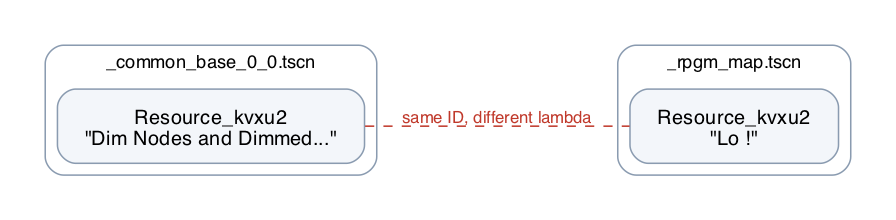

<details><summary>diagram source (graphviz)</summary>

```dot
digraph {
  subgraph cluster_base {
    label="_common_base_0_0.tscn"; fontname="Helvetica"; fontsize=12; color="#8a9bb0"; style="rounded";
    b [label="Resource_kvxu2\n\"Dim Nodes and Dimmed...\""];
  }
  subgraph cluster_map {
    label="_RPGM.tscn"; fontname="Helvetica"; fontsize=12; color="#8a9bb0"; style="rounded";
    m [label="Resource_kvxu2\n\"Lo !\""];
  }
  b -> m [label="same ID, different lambda", dir=none, style=dashed, color="#c0392b", fontcolor="#c0392b"];
}
```

</details>

`Resource_kvxu2` is not a global name. It means "the thing called `kvxu2` **in the file I am written in**".

| File | ID | Messages |
|---|---|---|
| `viewports/rpgm/common/common_events/_common_base_0_0.tscn` | `Resource_kvxu2` | "Dim Nodes and Dimmed Scripts denote..." |
| `viewports/rpgm/_RPGM.tscn` | `Resource_kvxu2` | "Lo !" |

Two different lambdas, two different files, one name. Which one a node gets depends only on **which file the node is written in**:

| The node is... | Written in | `Resource_kvxu2` means |
|---|---|---|
| An instance | The base file (the map only holds a link) | The base file's lambda: "Dim Nodes..." |
| Made local | The map file | The map file's lambda: "Lo !" |

That is what makes Make Local flip the message.


## 6. Putting it together

**Where things stand right now:**

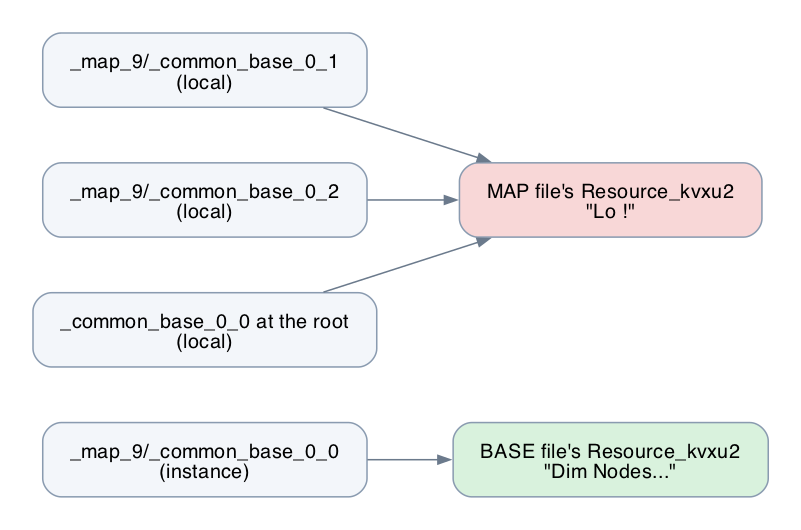

<details><summary>diagram source (graphviz)</summary>

```dot
digraph {
  i [label="_map_9/_common_base_0_0\n(instance)"];
  l1 [label="_map_9/_common_base_0_1\n(local)"];
  l2 [label="_map_9/_common_base_0_2\n(local)"];
  l3 [label="_common_base_0_0 at the root\n(local)"];
  base [label="BASE file's Resource_kvxu2\n\"Dim Nodes...\"", fillcolor="#d9f2dd"];
  map [label="MAP file's Resource_kvxu2\n\"Lo !\"", fillcolor="#f8d7d7"];
  i -> base;
  l1 -> map; l2 -> map; l3 -> map;
}
```

</details>

**How you got here.** The "Source" column says how sure each step is.

| Step | What happened | Source |
|---|---|---|
| 1 | The base scene was saved with its lambda `Resource_kvxu2` = "Dim Nodes..." | In the file |
| 2 | An instance in the map was made local. Its lambda ended up stored in the map file under the same ID, `Resource_kvxu2` | In the file (the map has that ID); *why* the ID was kept is my inference |
| 3 | Local nodes were duplicated. All of them point at that one map lambda (fact 3) | In the file: one definition, three nodes using it |
| 4 | You changed the message on "one specific node" to "Lo !". There is only one lambda, so all three changed | In the file |
| 5 | You add a **new instance**. It reads the base file, so it shows "Dim Nodes..." (fact 4) | You observed; matches the file |
| 6 | You click **Make Local**. The node is now written in the map, where `Resource_kvxu2` is the "Lo !" lambda (fact 5) | You observed; the exact engine step is my inference |
| 7 | The base scene appears to show "Lo !" | The file still says "Dim Nodes..."; a live object in memory looks changed (fact 1, section 8) |

**The three symptoms, each traced to a fact:**

| Symptom | Caused by |
|---|---|
| Instance shows "Dim Nodes..." | Fact 4: an instance reads the base file |
| Make Local flips it to "Lo !" | Fact 5: same ID, but now resolved in the map file |
| "I only changed one node" yet several say "Lo !" | Fact 3: those nodes share one lambda |
| Base "changed" without being touched | Fact 1: the file did not change; the editor shows live objects, and one of those looks changed |


## 7. Check the real files yourself

This reads the two scene files (read-only) and prints where each lambda lives and which nodes use it. It shows the **disk** world only. If the editor shows something different, the difference is unsaved live objects in memory (fact 1).


In [5]:
import os, re

root = os.getcwd()
while not os.path.exists(os.path.join(root, "project.godot")) and root != "/":
	root = os.path.dirname(root)

FILES = {
	"BASE": "viewports/rpgm/common/common_events/_common_base_0_0.tscn",
	"MAP":  "viewports/rpgm/_RPGM.tscn",
}

def read_scene(path):
	"""Return ({lambda_id: first message}, [(node path, [ids or None])])."""
	lambdas, users, block = {}, [], None
	for line in open(os.path.join(root, path), errors="ignore"):
		head = re.match(r'\[(sub_resource|node) (.*)\]', line)
		if head:
			attrs = dict(re.findall(r'(\w+)="([^"]*)"', head.group(2)))
			block = (head.group(1), attrs)
		elif block and block[0] == "sub_resource" and line.startswith("messages = "):
			first = re.search(r'\["((?:[^"\\]|\\.)*)"', line)
			lambdas[block[1]["id"]] = first.group(1)[:38] if first else "(empty)"
		elif block and block[0] == "node" and line.startswith("on_action = "):
			ids = re.findall(r'SubResource\("([^"]+)"\)|(null)', line.split("(", 1)[1])
			name = block[1].get("parent", ".").lstrip("./") + "/" + block[1]["name"]
			users.append((name.lstrip("/"), [a or None for a, _ in ids]))
	return lambdas, users

scenes = {tag: read_scene(path) for tag, path in FILES.items()}
clash = set(scenes["BASE"][0]) & set(scenes["MAP"][0])

for tag, (lambdas, users) in scenes.items():
	print(f"{tag}: {FILES[tag]}")
	for lambda_id in sorted(clash):
		print(f"   lambda {lambda_id}: \"{lambdas[lambda_id]}\"")
	for node, ids in users:
		if clash & set(ids) or None in ids:
			shown = ", ".join("EMPTY SLOT" if i is None else i for i in ids)
			print(f"   node   {node}  ->  [{shown}]")
	print()

print("IDs that exist in BOTH files (same name, different lambda):", sorted(clash) or "none")

BASE: viewports/rpgm/common/common_events/_common_base_0_0.tscn
   lambda Resource_kvxu2: "Dim Nodes and Dimmed Scripts denote no"
   node   _RPGM_Script  ->  [Resource_kvxu2]

MAP: viewports/rpgm/_RPGM.tscn
   lambda Resource_kvxu2: "Lo !"
   node   _map_9/_common_base_0_1/_RPGM_Script  ->  [Resource_kvxu2, Resource_nvfdq, EMPTY SLOT]
   node   _map_9/_common_base_0_2/_RPGM_Script  ->  [Resource_kvxu2, Resource_ctvm8]
   node   _common_base_0_0/_RPGM_Script  ->  [Resource_kvxu2]

IDs that exist in BOTH files (same name, different lambda): ['Resource_kvxu2']


In [6]:
# ----- student scratchpad -----

| If the output shows | It means |
|---|---|
| BASE lambda still says "Dim Nodes..." | The base file is intact |
| BASE lambda says "Lo !" | The base tab was saved while showing the wrong lambda; restore the message there |
| Several MAP nodes list the same ID | They share one lambda; editing one edits all |
| "IDs that exist in BOTH files" is not empty | The name clash is still there; Make Local can still land on the wrong one |
| `EMPTY SLOT` | A blank entry in a lambda list; `run_lambda_queue` will error when it reaches it |


## 8. Getting out, and the rules from here

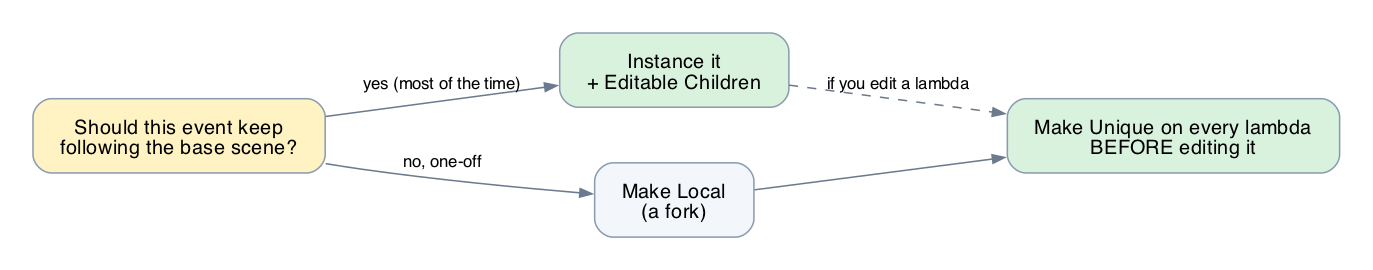

<details><summary>diagram source (graphviz)</summary>

```dot
digraph {
  q [label="Should this event keep\nfollowing the base scene?", fillcolor="#fff3c4"];
  yes [label="Instance it\n+ Editable Children", fillcolor="#d9f2dd"];
  no [label="Make Local\n(a fork)"];
  uniq [label="Make Unique on every lambda\nBEFORE editing it", fillcolor="#d9f2dd"];
  q -> yes [label="yes (most of the time)"];
  q -> no [label="no, one-off"];
  no -> uniq;
  yes -> uniq [label="if you edit a lambda", style=dashed];
}
```

</details>

**About symptom 3.** The file is intact, so it is one of these three. I cannot see your editor, so I do not know which:

| Where you see "Lo !" | What it is |
|---|---|
| A node named `_common_base_0_0` at the **root of the map** | Not the base. It is a made-local node that happens to have the same name as the base scene |
| The **base scene's own tab**, after a base-owned lambda was edited through an instance | Fact 1 directly: the tab and the instance show the same live object. The file on disk is still correct |
| The **base scene's own tab**, with no such edit | The editor showing the map's lambda in place of the base's (the ID clash). The file on disk is still correct |

To tell which: hover over the lambda in the Inspector. Its path ends in either `_RPGM.tscn::Resource_kvxu2` or `_common_base_0_0.tscn::Resource_kvxu2`.

**Clean-up, in order:**

| Step | Do | Why |
|---|---|---|
| 1 | Do **not** save the base scene tab while it shows "Lo !" | Saving would write "Lo !" into the base file for real |
| 2 | On that tab: Scene > Reload Saved Scene (or close without saving, reopen) | Brings back what is on disk |
| 3 | In the base scene: right-click the lambda > Make Unique, then save | Gives the base lambda a new ID, so it no longer matches the one in the map |
| 4 | On each made-local node that should have its own text: Make Unique on its lambda, then edit | Stops the three nodes sharing one lambda |
| 5 | Remove or fill the empty slot in `_map_9/_common_base_0_1`'s `on_action` | Avoids an error when the queue reaches it |
| 6 | Re-run the cell in section 7 | Confirms the clash list is empty |

**Working rules (Editable Children as your main workflow):**

| Rule | Why |
|---|---|
| Instance, tick Editable Children, edit the child nodes directly | Keeps the link to the base; your edits are saved as diffs in the map |
| Keep child names and nesting stable in the base scene | Diffs are stored by node path; a rename detaches them |
| Add extra children freely on an instance | They are saved in the map and survive base changes |
| Make Unique before editing any lambda that came from a template | Nodes are yours; the lambdas inside are shared until you say otherwise |
| Use Make Local only to fork | It cuts the link the other workflows preserve |
| For a variant you will reuse: New Inherited Scene | Change it once there, then instance the variant |

"Local to Scene" on the lambdas in the base scene should give every instance its own copy automatically. I have not confirmed it applies to lambdas inside an array in your Godot version, so test it with two instances before relying on it.

**What is certain and what is not:**

| Claim | Status |
|---|---|
| The base file holds "Dim Nodes...", the map file holds "Lo !", both under `Resource_kvxu2` | Read from the files |
| Three made-local nodes in the map share the "Lo !" lambda | Read from the files |
| Editing an instance never writes to the base file | How Godot scenes work |
| In the editor, the base tab and its instances show the same live object | As far as I know; not verified in your version |
| Make Local binds to the map's existing lambda *because* the IDs match | My inference; the hover check above confirms or refutes it |
| Which of the three things you are looking at in symptom 3 | Unknown until you check |
